# 2. Who does a hate-speech filter fail?

[Notebook 1](01_original_model.ipynb) ended with a model that looked accurate (86%) but caught 2% of hate speech. This notebook goes step by step:

1. **Build a better model** and test what each change does.
2. **Check its behaviour** on everyday posts, negation, identity terms and counter-speech.
3. **Audit for dialect bias**: are harmless tweets in African American English (AAE) flagged more often?
4. **Compare moderation policies**: what happens to people when a platform acts on the model?

The code lives in `src/ald/`; this notebook calls it and explains the results. `python run_all.py` runs the same experiments and writes every number to `results/`.

**Content note:** the datasets contain slurs and abusive language. No tweets are printed. The only example sentences are ordinary ones, plus two short test sentences about immigrants.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..", "src").resolve()))
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold, cross_val_predict

from ald import audits, checks, data, dialect, glove, models, policy
from ald.config import CLASSES, HATE, NEITHER, SEED
from ald.metrics import evaluate
from ald.pipeline import TextModel, clean, dialect_groups
from ald.text import clean_text, negation_tokens, original_tokens

INK, MUTED, BLUE, ORANGE, GREEN = "#2A2150", "#6B6492", "#4C6EF5", "#E8833A", "#2F9E77"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#E4DEF6", "axes.axisbelow": True, "font.size": 11})
pct = "{:.0%}".format

## Data

- **Davidson et al. (2017):** 24,783 tweets labelled hate, offensive or neither. The same 60/20/20 split as notebook 1. Validation data is used only to calibrate probabilities and choose policy thresholds.
- **OLID (Zampieri et al., 2019):** about 14,000 tweets labelled offensive or not, sampled more like an everyday feed. "Not offensive" maps to *neither*.

In [2]:
df = data.load_davidson()
train, val, test = data.split(df)
olid = {s: data.load_olid(s) for s in ("train", "val", "test")}
pd.DataFrame({"Davidson": [len(train), len(val), len(test)],
              "OLID": [len(olid[s]) for s in ("train", "val", "test")]}, index=["train", "validation", "test"])

,Davidson,OLID
train,14869,11916
validation,4957,1324
test,4957,860


## Step 1. The original model, as a baseline

Averaged GloVe vectors with an SVM (rbf, C = 10): the tuned model from notebook 1.

In [3]:
def glove_X(texts):
    return glove.embed([original_tokens(t) for t in texts])

original = models.original_models()["SVM (rbf, C=10, tuned)"].fit(glove_X(train.tweet), train.label)
original_labels = lambda texts: original.predict(glove_X(texts))
original_scores = lambda texts: original.decision_function(glove_X(texts))

def summary(name, y_true, y_pred):
    m = evaluate(y_true, y_pred)
    return {"model": name, "accuracy": m["accuracy"], "macro F1": m["macro_f1"],
            "hate recall": m["per_class"]["hate"]["recall"], "hate precision": m["per_class"]["hate"]["precision"]}

rows = [summary("Original: GloVe + SVM", test.label, original_labels(test.tweet))]
pd.DataFrame(rows).set_index("model").style.format("{:.1%}")

,accuracy,macro F1,hate recall,hate precision
model,,,,
Original: GloVe + SVM,85.9%,55.6%,2.1%,54.5%


**Macro F1** averages the three classes equally, so a model can't score well by ignoring the small hate class. It's a fairer headline number than accuracy here.

## Step 2. A better model, one change at a time

Each row adds one change to the row above:

| Change | Why | Source |
| --- | --- | --- |
| TF-IDF word and character n-grams, class-balanced logistic regression | Word pairs like "don't hate" carry meaning that averaged vectors lose. Character n-grams catch misspellings. Balancing stops the 6% hate class from being ignored. | Davidson et al. (2017) |
| + everyday tweets (OLID) | Davidson's tweets were collected by searching for hateful words, so the model rarely sees ordinary posts. | Zampieri et al. (2019) |
| + negation marking | Words after "not", "don't" and similar get a `neg_` prefix until the next punctuation mark. | Das & Chen (2001); Pang et al. (2002) |
| + identity swaps | Each training tweet that names a group gets a copy naming a different group with the same label, so a group's name alone can't signal abuse. | Park et al. (2018); Garg et al. (2019) |

In [4]:
print(negation_tokens(clean_text("I don't hate immigrants, I hate the new policy.")))

["don't", 'neg_hate', 'neg_immigrants', 'hate', 'the', 'new', 'policy']


Negation marking turns "hate" after "don't" into a different feature, `neg_hate`, so the model can learn that it means something else.

In [5]:
variants = [
    TextModel("TF-IDF + balanced LR"),
    TextModel("+ everyday tweets (OLID)", olid=True),
    TextModel("+ negation marking", olid=True, negation=True),
    TextModel("+ identity swaps (final)", olid=True, negation=True, swaps="all"),
]
for v in variants:
    v.fit(train, val, olid["train"], olid["val"])
    rows.append(summary(v.name, test.label, v.labels(test.tweet)))
first, final = variants[0], variants[-1]
pd.DataFrame(rows).set_index("model").style.format("{:.1%}")

,accuracy,macro F1,hate recall,hate precision
model,,,,
Original: GloVe + SVM,85.9%,55.6%,2.1%,54.5%
TF-IDF + balanced LR,88.4%,73.6%,47.2%,38.5%
+ everyday tweets (OLID),89.0%,73.3%,41.3%,38.9%
+ negation marking,89.2%,74.0%,43.7%,40.8%
+ identity swaps (final),89.1%,73.3%,40.9%,39.3%


The first change does most of the work on the Davidson test set: hate recall jumps from 2% to 47%. The later changes give up some of that (down to 41%) in exchange for better behaviour on ordinary speech, which the next step measures.

## Step 3. Behavioural checks

Accuracy can't show *how* a model fails. Each check tests one expected behaviour, in the style of CheckList (Ribeiro et al., 2020). Higher is better.

- **Everyday tweets not flagged:** OLID test tweets annotators marked not offensive.
- **Everyday examples not flagged:** 15 ordinary posts, including proud identity statements ("I'm a proud Muslim woman") and in-group slang.
- **Negation not called hate:** HateCheck sentences such as "I don't hate immigrants".
- **Same label across groups:** HateCheck templates filled with 7 different groups should get one label.
- **Counter-speech not called hate:** people quoting or calling out hate.

In [6]:
def check_row(name, label_fn, proba_fn):
    c = checks.run_all(label_fn, proba_fn)
    return {"model": name,
            "everyday tweets not flagged": c["everyday_speech"]["olid_pass_rate"],
            "everyday examples not flagged": c["everyday_speech"]["examples_pass_rate"],
            "negation not called hate": c["negation"]["not_called_hate_pass_rate"],
            "same label across groups": c["identity_swap"]["consistent_pass_rate"],
            "counter-speech not called hate": c["counter_speech"]["not_called_hate_pass_rate"]}

check_table = pd.DataFrame([check_row("Original: GloVe + SVM", original_labels, original_scores)]
                           + [check_row(v.name, v.labels, v.proba) for v in variants]).set_index("model")
check_table.style.format("{:.0%}")

,everyday tweets not flagged,everyday examples not flagged,negation not called hate,same label across groups,counter-speech not called hate
model,,,,,
Original: GloVe + SVM,76%,60%,100%,28%,100%
TF-IDF + balanced LR,81%,73%,60%,28%,59%
+ everyday tweets (OLID),92%,93%,92%,30%,83%
+ negation marking,92%,87%,95%,31%,87%
+ identity swaps (final),91%,87%,94%,39%,88%


The original model "passes" several checks only because it almost never says "hate", so it can't wrongly call anything hate either. Of the trained models, adding everyday tweets helps ordinary posts the most.

Here is what the final model does with a few sentences:

In [7]:
examples = ["Had a great day at the beach with my family", "I'm a proud Muslim woman",
            "Happy Pride month to all my LGBTQ friends", "yall really finna make me laugh today lol",
            "I hate immigrants", "I don't hate immigrants"]
probs = final.proba(examples)
pd.DataFrame({"sentence": examples, "label": [CLASSES[i] for i in final.labels(examples)],
              "P(hate)": probs[:, 0], "P(offensive)": probs[:, 1], "P(neither)": probs[:, 2]}) \
  .style.format({"P(hate)": pct, "P(offensive)": pct, "P(neither)": pct}).hide(axis="index")

sentence,label,P(hate),P(offensive),P(neither)
Had a great day at the beach with my family,neither,1%,28%,71%
I'm a proud Muslim woman,neither,2%,35%,63%
Happy Pride month to all my LGBTQ friends,neither,4%,32%,64%
yall really finna make me laugh today lol,neither,1%,41%,58%
I hate immigrants,offensive,4%,91%,5%
I don't hate immigrants,offensive,1%,94%,5%


The ordinary posts are left alone. But the last two sentences show a real weakness: the model calls both "offensive" with almost the same confidence, so it can't tell hating immigrants from *not* hating them. Negation marking helps on HateCheck's negation tests, but it doesn't fix every case.

## Step 4. HateCheck and identity terms

**HateCheck** (Röttger et al., 2021) has 3,728 short test cases in 29 categories, such as threats, slurs, negation and counter-speech. A hateful case counts as caught only if the model says *hate*: calling it "offensive" would let it through a hate policy.

**Identity terms** (Dixon et al., 2018): 38,282 harmless template sentences such as "I am a ___ person", filled with 50 identity terms. None should be flagged.

In [8]:
hc = {name: audits.hatecheck(fn) for name, fn in
      [("Original", original_labels), ("TF-IDF + balanced LR", first.labels), ("Final", final.labels)]}
idt = {name: audits.identity_terms(fn) for name, fn in
       [("Original", original_labels), ("TF-IDF + balanced LR", first.labels), ("Final", final.labels)]}
pd.DataFrame({name: {"HateCheck: hateful cases caught as hate": hc[name][0]["hate_detected"],
                     "HateCheck: harmless cases called hate": hc[name][0]["benign_wrongly_hate"],
                     "Identity sentences flagged": idt[name][0]["overall_false_flag_rate"]}
              for name in hc}).style.format("{:.0%}")

,Original,TF-IDF + balanced LR,Final
HateCheck: hateful cases caught as hate,3%,34%,14%
HateCheck: harmless cases called hate,2%,27%,8%
Identity sentences flagged,17%,20%,24%


The HateCheck categories the final model gets wrong most often:

In [9]:
worst = hc["Final"][1].head(8)
worst.assign(kind=np.where(worst.gold_hateful, "hateful", "not hateful"))[["functionality", "kind", "n", "accuracy"]] \
     .style.format({"accuracy": pct}).hide(axis="index")

functionality,kind,n,accuracy
phrase_question_h,hateful,140,2%
derog_neg_attrib_h,hateful,140,6%
negate_pos_h,hateful,140,8%
spell_char_del_h,hateful,140,9%
phrase_opinion_h,hateful,133,10%
derog_impl_h,hateful,140,10%
ref_subs_clause_h,hateful,140,12%
ref_subs_sent_h,hateful,133,13%


The identity terms most often flagged in harmless sentences, for the first and final models:

In [10]:
terms = idt["TF-IDF + balanced LR"][1][["false_flag_rate"]].rename(columns={"false_flag_rate": "TF-IDF + balanced LR"}) \
    .join(idt["Final"][1][["false_flag_rate"]].rename(columns={"false_flag_rate": "Final"}))
terms.sort_values("TF-IDF + balanced LR", ascending=False).head(10).style.format(pct)

,TF-IDF + balanced LR,Final
term,,
queer,100%,92%
white,100%,59%
straight,78%,36%
gay,77%,38%
muslim,58%,4%
younger,46%,9%
black,45%,36%
blind,41%,25%
male,41%,23%


The final model is more cautious: it calls far fewer harmless HateCheck cases hate (8%, down from 27%), but it also catches far less hate (14%, down from 34%). Identity swaps lowered the false flags for the worst terms (*Muslim* fell from 58% to 4%), yet overall slightly more identity sentences are flagged, and *queer* is still flagged almost every time.

There's no free lunch here: each change moves errors between groups of people, which is why the checks need to be reported separately rather than as one score.

## Step 5. Dialect audit

This follows Davidson, Bhattacharya & Weber (2019) and Sap et al. (2019). The TwitterAAE model (Blodgett, Green & O'Connor, 2016) estimates how much of each tweet's language is African American English or White-aligned English. A tweet counts as AAE- or White-aligned when more than 60% of its language comes from that dialect.

This measures **language, not the author's race**.

The test split alone has too few tweets in each group, so every tweet is predicted by a model trained on the other four-fifths of the data (5-fold cross-validation).

In [11]:
props = np.array([p if (p := dialect.proportions(t)) is not None else [np.nan] * 4 for t in df.tweet])
groups = dialect_groups(props, 0.6)
pd.Series(groups).value_counts().rename("tweets").to_frame()

,tweets
other,19257
aae,4439
white,1087


In [12]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_preds = {"Original": cross_val_predict(models.original_models()["SVM (rbf, C=10, tuned)"],
                                          glove_X(df.tweet), df.label, cv=folds)}
for name, v in (("TF-IDF + balanced LR", first), ("Final", final)):
    pred = np.empty(len(df), dtype=int)
    for tr, te in folds.split(df, df.label):
        X, y = v.training_data(df.iloc[tr], olid["train"])
        pred[te] = models.improved_model(negation=v.negation).fit(X, y).predict(clean(df.tweet.iloc[te]))
    cv_preds[name] = pred

disparity = {name: audits.dialect_disparity(df.tweet, df.label, p, groups) for name, p in cv_preds.items()}
a, w = disparity["Original"]["aae"], disparity["Original"]["white"]
print(f"Annotators labelled {a['gold_offensive_share']:.0%} of AAE-aligned tweets offensive, "
      f"against {w['gold_offensive_share']:.0%} of White-aligned tweets.")
print(f"Harmless tweets: {a['n_neither']} AAE-aligned, {w['n_neither']} White-aligned.")

pd.DataFrame({name: {"harmless AAE-aligned flagged": d["aae"]["false_flag_rate"],
                     "harmless White-aligned flagged": d["white"]["false_flag_rate"],
                     "ratio": d["false_flag_ratio"]} for name, d in disparity.items()}).T \
  .style.format({"harmless AAE-aligned flagged": pct, "harmless White-aligned flagged": pct, "ratio": "{:.1f}×"})

Annotators labelled 94% of AAE-aligned tweets offensive, against 29% of White-aligned tweets.
Harmless tweets: 90 AAE-aligned, 692 White-aligned.


,harmless AAE-aligned flagged,harmless White-aligned flagged,ratio
Original,87%,11%,8.1×
TF-IDF + balanced LR,33%,2%,13.6×
Final,37%,6%,6.5×


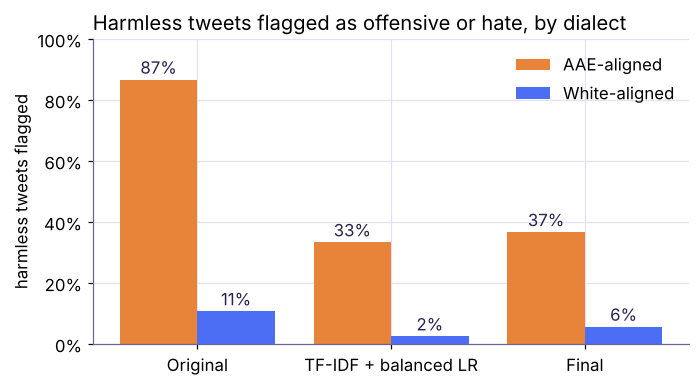

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.6))
names, x = list(disparity), np.arange(len(disparity))
aae = [disparity[n]["aae"]["false_flag_rate"] for n in names]
white = [disparity[n]["white"]["false_flag_rate"] for n in names]
ax.bar(x - 0.2, aae, 0.4, color=ORANGE, label="AAE-aligned")
ax.bar(x + 0.2, white, 0.4, color=BLUE, label="White-aligned")
for i in x:
    ax.text(i - 0.2, aae[i] + 0.02, pct(aae[i]), ha="center", color=INK)
    ax.text(i + 0.2, white[i] + 0.02, pct(white[i]), ha="center", color=INK)
ax.set_xticks(x, names)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda v, _: pct(v))
ax.set_ylabel("harmless tweets flagged")
ax.set_title("Harmless tweets flagged as offensive or hate, by dialect", loc="left")
ax.legend(frameon=False)
plt.show()

The bias starts with the labels: annotators marked most AAE-aligned tweets as offensive, and every model learns that pattern. The improved models flag far fewer harmless tweets overall, but the gap between groups stays large.

The cutoff isn't what drives this. Without any cutoff, the share of harmless tweets the final model flags rises steadily with the estimated share of AAE in a tweet:

In [14]:
audits.false_flag_by_aae_share(df.label, cv_preds["Final"], props[:, 0]) \
      .rename(columns={"bin": "estimated AAE share", "n": "harmless tweets", "false_flag_rate": "flagged"}) \
      .style.format({"flagged": pct}).hide(axis="index")

estimated AAE share,harmless tweets,flagged
"(-0.001, 0.2]",2463,7%
"(0.2, 0.4]",1263,11%
"(0.4, 0.6]",346,19%
"(0.6, 0.8]",84,35%
"(0.8, 1.0]",6,67%


## Step 6. Moderation policies

A platform doesn't just run a model; it decides what to do with the output. Using the final model on the test set, the policies below are compared.

- **Auto-remove:** delete whatever the model labels hate.
- **Remove anything flagged:** delete anything labelled hate *or* offensive.
- **Triage:** remove automatically only when the model is at least 80% precise (it never is, so nothing is removed without a person). Send the riskiest posts to a human reviewer, up to a review budget. Ask the authors of clearly offensive posts to reconsider ("nudge").

**Key assumption:** a reviewer always reaches the right label. Real reviewers make mistakes, and they can share the annotators' dialect bias, so the "0 wrongful removals" for triage holds only under this assumption.

In [15]:
test_groups = groups[test["index"].to_numpy()]
p_val, p_test = final.proba(val.tweet), final.proba(test.tweet)
y_val, y_test = val.label.to_numpy(), test.label.to_numpy()
th5 = policy.choose_thresholds(p_val, y_val, review_budget=0.05)
th10 = policy.choose_thresholds(p_val, y_val, review_budget=0.10)
print(f"Best precision the model reaches on hate: {th10['best_hate_precision']:.0%} (the bar for auto-removal is 80%)")

policies = {
    "Original model, auto-remove": policy.remove_predicted_hate(original_labels(test.tweet)),
    "Final model, auto-remove": policy.remove_predicted_hate(final.labels(test.tweet)),
    "Remove anything flagged": policy.decide(p_test, "remove_all_flagged"),
    "Triage, 5% to human review": policy.decide(p_test, "triage", th5),
    "Triage, 10% to human review": policy.decide(p_test, "triage", th10),
}
outcome = pd.DataFrame({n: policy.outcomes(a, y_test, test_groups) for n, a in policies.items()}).T
outcome[["hate_caught", "wrongful_removals", "wrongful_rate_aae", "wrongful_rate_white", "review_load"]] \
    .rename(columns={"hate_caught": "hate caught", "wrongful_removals": "harmless posts removed",
                     "wrongful_rate_aae": "AAE-aligned non-hate removed", "wrongful_rate_white": "White-aligned non-hate removed",
                     "review_load": "sent to a human"}) \
    .style.format({"hate caught": pct, "harmless posts removed": "{:.0f}", "AAE-aligned non-hate removed": pct,
                   "White-aligned non-hate removed": pct, "sent to a human": pct})

Best precision the model reaches on hate: 77% (the bar for auto-removal is 80%)


,hate caught,harmless posts removed,AAE-aligned non-hate removed,White-aligned non-hate removed,sent to a human
"Original model, auto-remove",2%,5,0%,0%,0%
"Final model, auto-remove",41%,181,3%,3%,0%
Remove anything flagged,86%,3837,98%,26%,0%
"Triage, 5% to human review",36%,0,0%,0%,6%
"Triage, 10% to human review",57%,0,0%,0%,11%


How much hate triage catches as the review budget grows, compared with auto-removal:

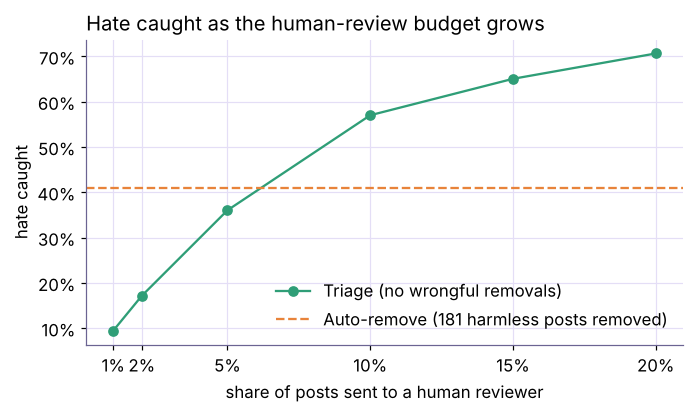

In [16]:
sweep = pd.DataFrame(policy.review_budget_sweep(p_val, y_val, p_test, y_test, test_groups))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(sweep.review_budget, sweep.hate_caught, marker="o", color=GREEN, label="Triage (no wrongful removals)")
auto = outcome.loc["Final model, auto-remove"]
ax.axhline(auto.hate_caught, color=ORANGE, ls="--",
           label=f"Auto-remove ({auto.wrongful_removals:.0f} harmless posts removed)")
ax.set_xticks(sweep.review_budget, [pct(b) for b in sweep.review_budget])
ax.yaxis.set_major_formatter(lambda v, _: pct(v))
ax.set_xlabel("share of posts sent to a human reviewer")
ax.set_ylabel("hate caught")
ax.set_title("Hate caught as the human-review budget grows", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.show()

With a 5% review budget, triage catches less hate than auto-removal. Somewhere between 5% and 10%, it overtakes it, and it never removes a harmless post (under the always-right-reviewer assumption).

What this shows:

- **The model's ranking is more useful than its verdict.** Its hard labels miss much of the hate, but the hate it misses is often still near the top of its risk scores, so a reviewer looking at the riskiest posts finds more.
- **Removing everything flagged is the worst option for fairness:** it silences almost every harmless AAE-aligned post.
- **The cost moves to people.** A 10% review budget means a reviewer reads one post in ten, and reviewing hate harms moderators' wellbeing (Steiger et al., 2021).

## What I took away

- **Accuracy hid the failure.** 86% accuracy with 2% of hate caught.
- **Better models moved the errors rather than removing them.** Identity words, counter-speech and dialect are still where the model fails, and they fall on particular groups.
- **Policy matters as much as the model.** Where a person stays in the loop, and what the model may do alone, changes who is harmed.

**Limits.** Older Twitter data (2017), English only, simulated reviewers who are always right, and a dialect model that estimates language rather than identity. Newer datasets to extend this are listed in [docs/datasets.md](../docs/datasets.md).